In [1]:
%pip install pandas scikit-learn matplotlib ucimlrepo


Note: you may need to restart the kernel to use updated packages.


# Fairness Audit of a Loan Model: Are Applicants Under 25 Treated Worse?

**Questions**
1. Does a loan-approval model approve applicants **under 25** less often than older applicants?
2. If we **remove the age column**, does the gap remain?

Data: Statlog German Credit (UCI). Tools: pandas, scikit-learn, matplotlib (Gradio only for the optional demo at the end).

---

## Step 1: Load the data (Statlog German Credit)

We fetch the **German Credit** dataset (UCI id=144) with the `ucimlrepo` package.

- The object returned by `fetch_ucirepo(id=144)` contains
  - `data.features` → 20 applicant columns (X)
  - `data.targets` → the label column `class` (y)
  - `variables` → a description table for each column (used in the next step to rename columns)
- Check: **1,000 rows**, **20 features**, and the count of each `class` value (should be good 700 / bad 300).

> The first run downloads the data, so it can take a few seconds.

**Backup:** if the UCI server is down (it once returned an HTTP 502 error), the `except` part loads the same data from the CSV files in `data/`. They were saved from this same download and checked to be identical. `try:` runs the download; if it raises any error, Python jumps to `except` instead of stopping.


In [2]:
import pandas as pd
from ucimlrepo import fetch_ucirepo

try:
    german = fetch_ucirepo(id=144)
    X = german.data.features        # applicant information (20 columns)
    y = german.data.targets         # label (1 column: class)
    variables = german.variables    # description of each column
except Exception as error:   # UCI server down or no internet -> use the copy saved in data/
    print("Download failed, using the saved copy in data/:", error)
    X = pd.read_csv("data/german_features.csv")
    y = pd.read_csv("data/german_targets.csv")
    variables = pd.read_csv("data/german_variables.csv")

print("X shape:", X.shape)   # should be (1000, 20)
print("y shape:", y.shape)   # should be (1000, 1)
print()
print("Count of each class value:")
print(y["class"].value_counts())

X.head()

X shape: (1000, 20)
y shape: (1000, 1)

Count of each class value:
class
1    700
2    300
Name: count, dtype: int64


,Attribute1,Attribute2,Attribute3,Attribute4,Attribute5,Attribute6,Attribute7,Attribute8,Attribute9,Attribute10,Attribute11,Attribute12,Attribute13,Attribute14,Attribute15,Attribute16,Attribute17,Attribute18,Attribute19,Attribute20
0,A11,6,A34,A43,1169,A65,A75,4,A93,A101,4,A121,67,A143,A152,2,A173,1,A192,A201
1,A12,48,A32,A43,5951,A61,A73,2,A92,A101,2,A121,22,A143,A152,1,A173,1,A191,A201
2,A14,12,A34,A46,2096,A61,A74,2,A93,A101,3,A121,49,A143,A152,1,A172,2,A191,A201
3,A11,42,A32,A42,7882,A61,A74,2,A93,A103,4,A122,45,A143,A153,1,A173,2,A191,A201
4,A11,24,A33,A40,4870,A61,A73,3,A93,A101,4,A124,53,A143,A153,2,A173,2,A191,A201


## Step 2-1: Give the columns readable names

Names like `Attribute1` and `Attribute2` say nothing about the data.
Using the `description` column of `variables`, we give each column a short English name.

- Build a dictionary `{old name: new name}` and apply it with `X.rename(columns=...)`.
- Most important: **`Attribute13` → `age`** (in years). This is the key column for the audit.
- At the end we print the original descriptions next to the new names to check each match by eye.

In [3]:
new_names = {
    "Attribute1":  "checking_status",          # status of checking account
    "Attribute2":  "duration_months",          # loan duration (months)
    "Attribute3":  "credit_history",           # past credit history
    "Attribute4":  "purpose",                  # purpose of the loan
    "Attribute5":  "credit_amount",            # loan amount (DM, Deutsche Mark)
    "Attribute6":  "savings",                  # savings account / bonds
    "Attribute7":  "employment_since",         # time at current job
    "Attribute8":  "installment_rate",         # installment as % of disposable income (1-4)
    "Attribute9":  "personal_status_sex",      # marital status + sex
    "Attribute10": "other_debtors",            # co-applicant / guarantor
    "Attribute11": "residence_since",          # time at current home (1-4)
    "Attribute12": "property",                 # property owned
    "Attribute13": "age",                      # age (years)  <- audited attribute
    "Attribute14": "other_installment_plans",  # other installment plans
    "Attribute15": "housing",                  # housing type
    "Attribute16": "existing_credits",         # number of existing credits at this bank
    "Attribute17": "job",                      # job
    "Attribute18": "num_dependents",           # number of people the applicant supports
    "Attribute19": "telephone",                # telephone registered
    "Attribute20": "foreign_worker",           # foreign worker
}

X = X.rename(columns=new_names)

# Check: original description next to the new name
check = variables[["name", "description", "type"]].copy()
check["new_name"] = check["name"].map(new_names)
check

,name,description,type,new_name
0,Attribute1,Status of existing checking account,Categorical,checking_status
1,Attribute2,Duration,Integer,duration_months
2,Attribute3,Credit history,Categorical,credit_history
3,Attribute4,Purpose,Categorical,purpose
4,Attribute5,Credit amount,Integer,credit_amount
5,Attribute6,Savings account/bonds,Categorical,savings
6,Attribute7,Present employment since,Categorical,employment_since
7,Attribute8,Installment rate in percentage of disposable i...,Integer,installment_rate
8,Attribute9,Personal status and sex,Categorical,personal_status_sex
9,Attribute10,Other debtors / guarantors,Categorical,other_debtors


## Step 2-2: A table of what each code (A11, ...) means

Categorical values are stored as codes such as `A11` or `A34`. Their meanings are not in the data; they are only in the original UCI documentation (`german.doc`). So we copy them into a table by hand.

- Each row = (column, code, meaning)
- **DM** = Deutsche Mark (German bank data published on UCI in 1994)
- `count`: how many applicants in the data have that code. **0 means the code is in the documentation but not in the data.**
  - `A47` (vacation): in the documentation only, 0 applicants
  - `A95` (female, single): in the documentation only, 0 applicants → so `personal_status_sex` cannot tell single women apart from other women (a data limitation)
- The last check makes sure no code in the data is missing from the table. **It should print "Missing codes: none".**

In [4]:
# (column, code, meaning) - source: UCI german.doc
codes = [
    ("checking_status", "A11", "balance < 0 DM"),
    ("checking_status", "A12", "0 <= balance < 200 DM"),
    ("checking_status", "A13", "balance >= 200 DM / salary paid in for 1+ year"),
    ("checking_status", "A14", "no checking account"),

    ("credit_history", "A30", "no credits taken / all paid back duly"),
    ("credit_history", "A31", "all credits at this bank paid back duly"),
    ("credit_history", "A32", "existing credits paid back duly till now"),
    ("credit_history", "A33", "delay in paying off in the past"),
    ("credit_history", "A34", "critical account / credits at other banks"),

    ("purpose", "A40", "car (new)"),
    ("purpose", "A41", "car (used)"),
    ("purpose", "A42", "furniture/equipment"),
    ("purpose", "A43", "radio/television"),
    ("purpose", "A44", "domestic appliances"),
    ("purpose", "A45", "repairs"),
    ("purpose", "A46", "education"),
    ("purpose", "A47", "vacation (not in data)"),
    ("purpose", "A48", "retraining"),
    ("purpose", "A49", "business"),
    ("purpose", "A410", "others"),

    ("savings", "A61", "< 100 DM"),
    ("savings", "A62", "100 to < 500 DM"),
    ("savings", "A63", "500 to < 1000 DM"),
    ("savings", "A64", ">= 1000 DM"),
    ("savings", "A65", "unknown / no savings account"),

    ("employment_since", "A71", "unemployed"),
    ("employment_since", "A72", "< 1 year"),
    ("employment_since", "A73", "1 to < 4 years"),
    ("employment_since", "A74", "4 to < 7 years"),
    ("employment_since", "A75", ">= 7 years"),

    ("personal_status_sex", "A91", "male: divorced/separated"),
    ("personal_status_sex", "A92", "female: divorced/separated/married"),
    ("personal_status_sex", "A93", "male: single"),
    ("personal_status_sex", "A94", "male: married/widowed"),
    ("personal_status_sex", "A95", "female: single (not in data)"),

    ("other_debtors", "A101", "none"),
    ("other_debtors", "A102", "co-applicant"),
    ("other_debtors", "A103", "guarantor"),

    ("property", "A121", "real estate"),
    ("property", "A122", "building society savings / life insurance"),
    ("property", "A123", "car or other"),
    ("property", "A124", "unknown / no property"),

    ("other_installment_plans", "A141", "bank"),
    ("other_installment_plans", "A142", "stores"),
    ("other_installment_plans", "A143", "none"),

    ("housing", "A151", "rent"),
    ("housing", "A152", "own"),
    ("housing", "A153", "for free"),

    ("job", "A171", "unemployed / unskilled non-resident"),
    ("job", "A172", "unskilled resident"),
    ("job", "A173", "skilled employee / official"),
    ("job", "A174", "management / self-employed / highly qualified"),

    ("telephone", "A191", "none"),
    ("telephone", "A192", "yes, in customer's name"),

    ("foreign_worker", "A201", "yes"),
    ("foreign_worker", "A202", "no"),
]

code_table = pd.DataFrame(codes, columns=["column", "code", "meaning"])

# Count how many applicants have each code
code_table["count"] = [(X[col] == code).sum() for col, code in zip(code_table["column"], code_table["code"])]

# Check: is any code in the data missing from the table?
missing = []
for col in code_table["column"].unique():
    for code in X[col].unique():
        if code not in code_table["code"].values:
            missing.append((col, code))
print("Missing codes:", missing if missing else "none")

pd.set_option("display.max_rows", 100)
code_table

Missing codes: none


,column,code,meaning,count
0,checking_status,A11,balance < 0 DM,274
1,checking_status,A12,0 <= balance < 200 DM,269
2,checking_status,A13,balance >= 200 DM / salary paid in for 1+ year,63
3,checking_status,A14,no checking account,394
4,credit_history,A30,no credits taken / all paid back duly,40
5,credit_history,A31,all credits at this bank paid back duly,49
6,credit_history,A32,existing credits paid back duly till now,530
7,credit_history,A33,delay in paying off in the past,88
8,credit_history,A34,critical account / credits at other banks,293
9,purpose,A40,car (new),234


## Step 3: Recode the target as 1 = good, 0 = bad

**First, check the original coding** in two places before changing anything.
1. The description table (`variables`), row `class` → `1 = Good, 2 = Bad`
2. The actual values → `1` for 700 applicants, `2` for 300

**Recoding rule**
| Original | Meaning | New value |
|---|---|---|
| 1 | Good (repaid) | **1** = OK to approve |
| 2 | Bad (risk of default) | **0** |

- Why? Later we read "the model predicts 1" as "approve", which makes approval rates easy to compute: the mean of a 0/1 column is the share of 1s.
- `y` is a one-column table (DataFrame), so we take the column as a Series with `y["class"]` and recode it with `.map({1: 1, 2: 0})`.
- Check: after recoding there should be 700 ones, 300 zeros, and 0 unmapped values (NaN).

In [5]:
# 1) Check the original coding
print("Description:", variables.loc[variables["name"] == "class", "description"].values[0])
print("Original value counts:")
print(y["class"].value_counts())
print()

# 2) 1 = good -> 1,  2 = bad -> 0
target = y["class"].map({1: 1, 2: 0})
target.name = "good"

# 3) Check
print("Value counts after recoding:")
print(target.value_counts())
print("Unmapped values (NaN):", target.isna().sum())   # should be 0
print("Good rate:", target.mean())                     # should be 0.7

Description: 1 = Good, 2 = Bad
Original value counts:
class
1    700
2    300
Name: count, dtype: int64

Value counts after recoding:
good
1    700
0    300
Name: count, dtype: int64
Unmapped values (NaN): 0
Good rate: 0.7


## Step 4: Create the under-25 and 25+ groups

We split applicants into the two groups we will compare.
- `age < 25` → **"under 25"**
- `age >= 25` → **"25+"**

**Why 25?** Fairness studies and tools that use this dataset single out young applicants around age 25, so using the same cut-off makes our results comparable.
> Note: IBM's fairness toolkit AIF360 defines the privileged group as age **over** 25, so it places applicants who are exactly 25 differently from us. We follow the competition brief and use **under 25**.

**Code**
- `X["age"] < 25` gives a True/False column.
- `.map({True: "under 25", False: "25+"})` turns it into group names, stored in `group`.
- `pd.DataFrame({"group": group, "good": target})` puts the two columns side by side.
- `groupby("group")` groups applicants, and on `"good"` we compute
  - `count` = number of applicants
  - `mean` = good rate (good is 1, so the mean is the share)

**Check:** the two group sizes should add up to 1,000.

This table uses the **actual outcomes recorded in the data**, not a model. If under-25 applicants already have a lower good rate, a model can learn that gap. Keep this in mind.

In [6]:
group = (X["age"] < 25).map({True: "under 25", False: "25+"})
group.name = "group"

df = pd.DataFrame({"group": group, "good": target})

group_table = df.groupby("group")["good"].agg(["count", "mean"])
group_table.columns = ["count", "good rate"]
print("Total count:", group_table["count"].sum())   # should be 1000
print("Good-rate gap (25+ minus under 25):",
      round(group_table.loc["25+", "good rate"] - group_table.loc["under 25", "good rate"], 3))

group_table

Total count: 1000
Good-rate gap (25+ minus under 25): 0.129


,count,good rate
group,,
25+,851,0.719154
under 25,149,0.590604


## Step 5: Train / test split (70% / 30%)

To check that the model works on **people it has never seen**, we set aside applicants that are not used for training.
- **train (70%, 700 applicants)**: used to fit models.
- **test (30%, 300 applicants)**: used only for final evaluation. **Never used for tuning.** If we changed settings after looking at test scores, the score would be fitted to the test set and would no longer measure performance on unseen people.

**`train_test_split` options**
- `test_size=0.3`: 30% goes to test.
- `stratify=target`: keeps the good/bad ratio (70:30) the same in train and test. Otherwise bad applicants could pile up on one side by chance.
- `random_state=42`: fixes the shuffle so every run produces the same split (reproducible).

**Keeping the group labels**
- `group` was not split, so `group.loc[X_test.index]` takes **the groups of the people who ended up in test**.
- `.index` is each applicant's original row number, so the same people are matched exactly.

**Check**
- Sizes: train 700, test 300
- Good rate: 0.7 in both
- Under-25 applicants in test: about 45 (roughly 30% of 149). Stratification is on good/bad, not age, so the age-group split is not exact.

In [7]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, target,
    test_size=0.3,
    stratify=target,
    random_state=42,
)

# Age group of each test applicant (matched by row number)
group_test = group.loc[X_test.index]

print("train shape:", X_train.shape, " test shape:", X_test.shape)
print("train good rate:", round(y_train.mean(), 3), " test good rate:", round(y_test.mean(), 3))
print()
print("Test applicants per group:")
print(group_test.value_counts())

train shape: (700, 20)  test shape: (300, 20)
train good rate: 0.7  test good rate: 0.7

Test applicants per group:
group
25+         253
under 25     47
Name: count, dtype: int64


## Step 6: Baseline - approve everyone

Before building a model, we measure the score of **"approve everyone, no questions asked"**. This is the **baseline**.
- If a model scores below this, there is no reason to use it.

**Accuracy** = share of predictions that match the true label
- Approve everyone = predict 1 (good) for every applicant
- Then only the truly good applicants are predicted correctly, so accuracy = test good rate = **0.7**.
- In other words, on this data "70% comes for free". What matters is how far a model gets above 0.7.

**Approval rate by group**
- Approval rate = share of a group predicted 1 (approved) = mean of the predictions
- Everyone is approved, so both groups have approval rate 1.0 and **gap = 0**
- By the approval-rate gap alone this looks fair, but it is useless because it also approves every bad applicant. Accuracy and fairness have to be checked separately.

**Code**
- `[1] * len(y_test)`: a list of 1s, one per test applicant (300) → approve everyone
- `pd.Series(..., index=X_test.index)`: attaches the test row numbers so predictions line up with `group_test`
- `accuracy_score(true, predicted)`: scikit-learn's accuracy function
- `.groupby(group_test).mean()`: mean prediction per group = approval rate per group
- Results are stored in `baseline_acc`, `baseline_rates`, `baseline_gap` for the Step 8 table.

In [8]:
from sklearn.metrics import accuracy_score

# Approve everyone: predict 1 (approve) for all 300 test applicants
baseline_pred = pd.Series([1] * len(y_test), index=X_test.index)

baseline_acc = accuracy_score(y_test, baseline_pred)

# Approval rate per group = mean prediction per group
baseline_rates = baseline_pred.groupby(group_test).mean()
baseline_gap = baseline_rates["25+"] - baseline_rates["under 25"]

print("Baseline accuracy:", round(baseline_acc, 3))   # should be 0.7
print()
print("Approval rate by group:")
print(baseline_rates)
print()
print("Gap (25+ minus under 25):", round(baseline_gap, 3))   # should be 0

Baseline accuracy: 0.7

Approval rate by group:
group
25+         1.0
under 25    1.0
dtype: float64

Gap (25+ minus under 25): 0.0


## Step 7: Model 1 - logistic regression (with age)

We predict good/bad from **all** 20 columns, including `age`. (A model without age comes next.)

### Preprocessing: the model only accepts numbers
**1) 13 categorical columns → one-hot encoding**
- Codes like `A11` and `A12` cannot be used in arithmetic, so we make one 0/1 column per code.
- Example: if `checking_status` is `A11` → `checking_status_A11 = 1`, and the `A12`, `A13`, `A14` columns = 0
- `handle_unknown="ignore"`: if a code appears in test but not in train, it becomes all zeros instead of raising an error.

**2) 7 numeric columns → scaling (`StandardScaler`)**
- `credit_amount` is in the thousands while `num_dependents` is 1-2. Very different scales make logistic regression harder to fit.
- Each column becomes **(value - mean) / standard deviation**, so all are on a similar scale.
- The mean and standard deviation are computed **on train only**. The `Pipeline` below only sees train when it is fitted, so no test information leaks in.

### Putting it together
- `ColumnTransformer`: decides which preprocessing goes to which columns.
- `Pipeline`: chains preprocessing → model. One line, `model1.fit(X_train, y_train)`, fits both.
- `LogisticRegression(max_iter=1000)`: default settings. We only raise the iteration limit so it fully converges. **No tuning, so the test set was never used for tuning.**

### Evaluation (test set)
- `model1.predict(X_test)`: approve (1) if the probability of good is above 0.5, otherwise reject (0)
- Accuracy, plus the approval rate per group and **gap = 25+ approval rate - under-25 approval rate**, computed as in Step 6.
- A positive gap means under-25 applicants are approved less often.

In [9]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

categorical_cols = [
    "checking_status", "credit_history", "purpose", "savings", "employment_since",
    "personal_status_sex", "other_debtors", "property", "other_installment_plans",
    "housing", "job", "telephone", "foreign_worker",
]
numeric_cols = [
    "duration_months", "credit_amount", "installment_rate", "residence_since",
    "age", "existing_credits", "num_dependents",
]
print("Categorical:", len(categorical_cols), "/ numeric:", len(numeric_cols))   # 13 / 7

preprocess = ColumnTransformer([
    ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_cols),
    ("num", StandardScaler(), numeric_cols),
])

model1 = Pipeline([
    ("preprocess", preprocess),
    ("logreg", LogisticRegression(max_iter=1000)),
])

# Fit on train only
model1.fit(X_train, y_train)

# Evaluate on test
model1_pred = pd.Series(model1.predict(X_test), index=X_test.index)

model1_acc = accuracy_score(y_test, model1_pred)
model1_rates = model1_pred.groupby(group_test).mean()
model1_gap = model1_rates["25+"] - model1_rates["under 25"]

print("Model 1 accuracy:", round(model1_acc, 3))
print()
print("Approval rate by group:")
print(model1_rates.round(3))
print()
print("Gap (25+ minus under 25):", round(model1_gap, 3))

Categorical: 13 / numeric: 7
Model 1 accuracy: 0.74

Approval rate by group:
group
25+         0.771
under 25    0.660
dtype: float64

Gap (25+ minus under 25): 0.111


## Step 8: Comparison table - baseline vs model 1

We collect the values saved in Steps 6 and 7 into one table. All numbers are on the **test set (300 applicants)**.

| Column | Meaning |
|---|---|
| `accuracy` | share of predictions that match the true label |
| `approval_under25` | share of under-25 applicants approved (predicted 1) |
| `approval_25plus` | share of 25+ applicants approved |
| `gap` | 25+ approval rate - under-25 approval rate (positive = under 25 approved less often) |
| `n_test_under25`, `n_test_25plus` | test applicants per group |

**Code**
- One row = one dictionary (`{"column name": value}`)
- A list of two dictionaries passed to `pd.DataFrame(...)` gives a two-row table.
- `.set_index("model")`: uses the model name as the row label.
- The group sizes are the same for both rows (same test set). We still show them because **only 47 test applicants are under 25**, so one person moves that group's approval rate by about 2 percentage points.

In [10]:
n_under25 = (group_test == "under 25").sum()
n_25plus = (group_test == "25+").sum()

rows = [
    {
        "model": "Baseline (approve all)",
        "accuracy": baseline_acc,
        "approval_under25": baseline_rates["under 25"],
        "approval_25plus": baseline_rates["25+"],
        "gap": baseline_gap,
        "n_test_under25": n_under25,
        "n_test_25plus": n_25plus,
    },
    {
        "model": "Model 1 (LogReg, with age)",
        "accuracy": model1_acc,
        "approval_under25": model1_rates["under 25"],
        "approval_25plus": model1_rates["25+"],
        "gap": model1_gap,
        "n_test_under25": n_under25,
        "n_test_25plus": n_25plus,
    },
]

comparison = pd.DataFrame(rows).set_index("model")
comparison.round(3)

,accuracy,approval_under25,approval_25plus,gap,n_test_under25,n_test_25plus
model,,,,,,
Baseline (approve all),0.70,1.00,1.000,0.000,47,253
"Model 1 (LogReg, with age)",0.74,0.66,0.771,0.111,47,253


## Step 9: Model 2 - logistic regression without the age column

**Second question:** if we remove `age` from the model, does the approval gap between under-25 and 25+ applicants disappear?

**Why check this?** A common belief is "if the model never sees age, it cannot discriminate by age" (*fairness through unawareness*). But if other columns are related to age, the model can still use age information indirectly through them. Such columns are called **proxy variables**. Candidates in this data:
- `employment_since`: younger people have shorter job tenure
- `housing`: younger people rent more often than they own
- `personal_status_sex`: marital status
- `property`, `savings`: younger people have less property and savings

**Only one thing changes from model 1**
- `numeric_cols_no_age` = `numeric_cols` without `"age"` (6 numeric columns).
- `.drop(columns="age")` removes `age` from X for both training and prediction.
- Everything else (one-hot, scaling, default LogisticRegression, same train/test split) is **identical** to model 1, so any difference comes from the age column.

**Note:** `age` is removed only from the model's inputs. We still use age to form the groups (`group_test`), because an auditor needs to know age to measure the gap.

**Extra check:** count how many test predictions differ between model 1 and model 2. If decisions barely change, model 1 was not leaning on the age column itself.

In [11]:
# Same setup as model 1, minus age
numeric_cols_no_age = [c for c in numeric_cols if c != "age"]
print("Numeric (without age):", numeric_cols_no_age)   # 6 columns

preprocess_no_age = ColumnTransformer([
    ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_cols),
    ("num", StandardScaler(), numeric_cols_no_age),
])

model2 = Pipeline([
    ("preprocess", preprocess_no_age),
    ("logreg", LogisticRegression(max_iter=1000)),
])

# Train and predict without the age column
X_train_no_age = X_train.drop(columns="age")
X_test_no_age = X_test.drop(columns="age")

model2.fit(X_train_no_age, y_train)
model2_pred = pd.Series(model2.predict(X_test_no_age), index=X_test.index)

model2_acc = accuracy_score(y_test, model2_pred)
model2_rates = model2_pred.groupby(group_test).mean()   # groups still defined by age
model2_gap = model2_rates["25+"] - model2_rates["under 25"]

print("Model 2 accuracy:", round(model2_acc, 3))
print()
print("Approval rate by group:")
print(model2_rates.round(3))
print()
print("Gap (25+ minus under 25):", round(model2_gap, 3))
print()

# Extra check: how many predictions differ from model 1
different = model1_pred != model2_pred
print("Predictions different from model 1:", different.sum(), "of 300")
print(different.groupby(group_test).sum())

Numeric (without age): ['duration_months', 'credit_amount', 'installment_rate', 'residence_since', 'existing_credits', 'num_dependents']
Model 2 accuracy: 0.747

Approval rate by group:
group
25+         0.771
under 25    0.660
dtype: float64

Gap (25+ minus under 25): 0.111

Predictions different from model 1: 4 of 300
group
25+         4
under 25    0
dtype: int64


## Step 10: Final comparison - actual outcomes vs baseline vs model 1 vs model 2

We add two rows to the Step 8 table.

**1) Model 2 (without age)**: results from Step 9

**2) Actual (test good rate)**: not a model prediction but the **true labels of the 300 test applicants**.
- In this row the "approval" columns hold each group's actual good rate. Read it as "what the approval rates would be if every decision were correct".
- This row is what lets us interpret a model's gap:
  - model gap > actual gap → the model **widened** the gap already in the data
  - model gap ≈ actual gap → the model **reproduced** it
  - model gap < actual gap → the model **narrowed** it
- Accuracy has no meaning for the true labels themselves, so it is left empty (`NaN`).

**Code**
- Reuses the Step 8 `rows` list (2 rows). `rows + [...]` creates a **new list** with two more rows, without changing the original, so re-running this cell never duplicates rows.
- `y_test.groupby(group_test).mean()`: mean of the true labels (good = 1) per group = actual good rate per group
- `float("nan")`: an empty value (accuracy column)

In [12]:
# Actual good rate of the 300 test applicants, by group
actual_rates = y_test.groupby(group_test).mean()
actual_gap = actual_rates["25+"] - actual_rates["under 25"]

final_rows = rows + [
    {
        "model": "Model 2 (LogReg, without age)",
        "accuracy": model2_acc,
        "approval_under25": model2_rates["under 25"],
        "approval_25plus": model2_rates["25+"],
        "gap": model2_gap,
        "n_test_under25": n_under25,
        "n_test_25plus": n_25plus,
    },
    {
        "model": "Actual (test good rate)",
        "accuracy": float("nan"),
        "approval_under25": actual_rates["under 25"],
        "approval_25plus": actual_rates["25+"],
        "gap": actual_gap,
        "n_test_under25": n_under25,
        "n_test_25plus": n_25plus,
    },
]

final_comparison = pd.DataFrame(final_rows).set_index("model")
final_comparison.round(3)

,accuracy,approval_under25,approval_25plus,gap,n_test_under25,n_test_25plus
model,,,,,,
Baseline (approve all),0.700,1.000,1.000,0.000,47,253
"Model 1 (LogReg, with age)",0.740,0.660,0.771,0.111,47,253
"Model 2 (LogReg, without age)",0.747,0.660,0.771,0.111,47,253
Actual (test good rate),NaN,0.553,0.727,0.174,47,253


## Step 11: Finding proxies - can the other columns tell who is under 25?

In Step 9 the gap stayed the same after removing `age`. **Is age information hidden in the other columns?** We measure it directly.

**Method: build an "age detector"**
- Inputs: the 19 columns **without** `age` (the same inputs as model 2)
- Label: not good/bad, but **"is this applicant under 25?"** (1 = under 25, 0 = 25+)
- Model: the same preprocessing (one-hot + scaling) and default `LogisticRegression` as model 2
- **Fit on train, evaluate on test.** No tuning.

If this model recognizes age groups well, age information survives in the other columns even after the `age` column is deleted, and model 2 can use it too.

**Metric: ROC AUC**
- The model gives each applicant a "probability of being under 25" (`predict_proba`).
- **AUC = the chance that, for a randomly chosen under-25 applicant and a randomly chosen 25+ applicant, the model gives the under-25 one the higher probability.**
  - **0.5** = a coin flip → **no age information** in the other columns
  - **1.0** = always correct → the other columns reveal the age group **perfectly**
  - **The higher above 0.5**, the more age information is hidden in the other columns
- **Why AUC instead of accuracy?** Only about 15% of applicants are under 25, so predicting "everyone is 25+" already gives 85% accuracy. AUC is not fooled by this imbalance.

**Code**
- `(X_train["age"] < 25).astype(int)`: turns True/False into 1/0 to make the age label. `age` is used **only to build the label**; it is **not among the model's inputs** (`X_train_no_age`).
- `clone(preprocess_no_age)`: makes a fresh, unfitted **copy** of model 2's preprocessing. Reusing the same object would refit the preprocessing inside model 2.
- `predict_proba(...)[:, 1]`: keeps only the "probability of under 25" column.
- `roc_auc_score(true labels, probabilities)`: computes the AUC.

In [13]:
from sklearn.base import clone
from sklearn.metrics import roc_auc_score

# Age label: 1 = under 25, 0 = 25+  (age used only to build the label)
is_young_train = (X_train["age"] < 25).astype(int)
is_young_test = (X_test["age"] < 25).astype(int)
print("Share under 25 in train:", round(is_young_train.mean(), 3))

# Age detector: inputs are the 19 non-age columns (same inputs and setup as model 2)
age_detector = Pipeline([
    ("preprocess", clone(preprocess_no_age)),
    ("logreg", LogisticRegression(max_iter=1000)),
])
age_detector.fit(X_train_no_age, is_young_train)

# Predict "probability of under 25" on test -> AUC
young_prob = age_detector.predict_proba(X_test_no_age)[:, 1]
age_auc = roc_auc_score(is_young_test, young_prob)

print("Age-detector ROC AUC (test):", round(age_auc, 3))
print("0.5 = no age information / 1.0 = age group revealed perfectly")

Share under 25 in train: 0.146
Age-detector ROC AUC (test): 0.836
0.5 = no age information / 1.0 = age group revealed perfectly


## Step 12: Top 5 inputs that reveal age

Which inputs did the Step 11 age detector use to spot under-25 applicants? Logistic regression has one **coefficient** per input.

**Reading a coefficient**
- **Positive (+)**: this value **raises** the probability of being under 25 → a trait of younger applicants
- **Negative (-)**: this value **lowers** it → a trait of older applicants
- **Larger absolute value** = reveals age more strongly. So we take `abs()` and keep the 5 largest.

**Reading input names**
- After preprocessing, names look like `cat__housing_A151`.
  - `cat__` = one-hot encoded categorical column
  - `num__` = scaled numeric column
- One-hot encoding splits a column into one input per code. For example, `housing` becomes `A151`, `A152`, `A153`. We attach each code's meaning from the Step 2-2 `code_table`.

**Caution**
- A coefficient is the effect "with all other inputs held the same", and for one-hot codes it is **relative to the other codes of the same column**.
- A coefficient shows that a trait **goes together with** age (correlation), not that it **causes** age.

**Code**
- `age_detector.named_steps["preprocess"].get_feature_names_out()`: list of input names after preprocessing
- `age_detector.named_steps["logreg"].coef_[0]`: one coefficient per input (same order as the names)
- `pd.Series(coefficients, index=names)` → coefficients labeled with their input names
- `.abs().sort_values(ascending=False).head(5).index`: names of the 5 largest in absolute value
- `meaning`: dictionary from `"cat__column_code"` to the code's meaning, built from `code_table`.

In [14]:
# Input names and coefficients of the age detector
feature_names = age_detector.named_steps["preprocess"].get_feature_names_out()
age_coef = pd.Series(age_detector.named_steps["logreg"].coef_[0], index=feature_names)

# The 5 largest in absolute value = inputs that reveal age most strongly
top5 = age_coef.abs().sort_values(ascending=False).head(5).index

# Attach code meanings: "cat__column_code" -> meaning
meaning = {}
for col, code, text in zip(code_table["column"], code_table["code"], code_table["meaning"]):
    meaning["cat__" + col + "_" + code] = text

proxy_table = pd.DataFrame({
    "meaning": [meaning.get(name, "") for name in top5],
    "age coef (+ = younger)": age_coef[top5].round(3),
})
proxy_table

,meaning,age coef (+ = younger)
cat__personal_status_sex_A91,male: divorced/separated,-0.996
cat__job_A174,management / self-employed / highly qualified,-0.916
cat__employment_since_A75,>= 7 years,-0.908
cat__housing_A151,rent,0.848
cat__purpose_A49,business,-0.680


## Step 13: How much do these inputs affect model 2's approval decision?

The Step 12 top 5 are inputs that reveal age. But revealing age only creates a gap **if the input is also used for approval**. So we put the coefficients these same 5 inputs received in **model 2 (the approval model without age)** next to them.

**Reading the two coefficients together**
| Age coef | Approval coef | Meaning |
|---|---|---|
| + (younger trait) | - (approval ↓) | a trait common among young applicants **lowers approval** → hurts under 25, **a channel for the gap** |
| - (older trait) | + (approval ↑) | a trait common among older applicants **raises approval** → favors 25+, also **a channel for the gap** |
| either sign | near 0 | reveals age but is barely used for approval → little effect on the gap |

So when **the two signs are opposite** and **the approval coefficient is large**, the input is likely a channel for the age gap.

**Code**
- `model2.named_steps["preprocess"].get_feature_names_out()` and `model2.named_steps["logreg"].coef_[0]`: model 2's labeled coefficients, built as in Step 12.
- `approve_coef[top5]`: model 2's coefficients for the 5 names chosen in Step 12.
- Both models use the same inputs (`X_train_no_age`) and the same preprocessing setup, so the input names match.

**Caution:** as in Step 12, coefficients are relative to other codes of the same column and show association, not cause.

In [15]:
# Input names and coefficients of model 2 (approval model without age)
model2_names = model2.named_steps["preprocess"].get_feature_names_out()
approve_coef = pd.Series(model2.named_steps["logreg"].coef_[0], index=model2_names)

# Add model 2's approval coefficient next to the Step 12 table
proxy_table["approval coef (+ = approve more)"] = approve_coef[top5].round(3)
proxy_table

,meaning,age coef (+ = younger),approval coef (+ = approve more)
cat__personal_status_sex_A91,male: divorced/separated,-0.996,-0.080
cat__job_A174,management / self-employed / highly qualified,-0.916,0.232
cat__employment_since_A75,>= 7 years,-0.908,-0.048
cat__housing_A151,rent,0.848,-0.437
cat__purpose_A49,business,-0.680,0.002


## Step 14: Gap bar chart (for the presentation)

One chart of the `gap` column from the Step 10 table. Gap = 25+ approval rate - under-25 approval rate; larger means under-25 applicants are approved less often.

**Design**
- 4 bars: Actual (test good rate), Baseline, Model 1, Model 2
- **Actual in gray**, models in **blue**. Actual is not a model but the gap already present in the data, so it serves as the reference for the models.
- Values are written on top of the bars so no one has to read the axis.
- The subtitle notes that only 47 test applicants are under 25 (one person moves that group's rate by about 2 points).

**Code**
- `final_comparison["gap"]`: the gap column of the Step 10 table.
- `.loc[[...]]`: picks rows in display order.
- `plt.subplots(figsize=(7, 4))`: a figure 7 inches wide, 4 inches tall.
- `ax.bar(names, values, color=colors)`: draws the bars.
- `ax.text(x, y, text)`: writes each value above its bar. `f"{v:.3f}"` means three decimal places.
- `ax.spines[...].set_visible(False)`: removes the top and right borders for a cleaner look.
- `fig.savefig("gap_chart.png", dpi=200)`: saves a PNG for the slides.

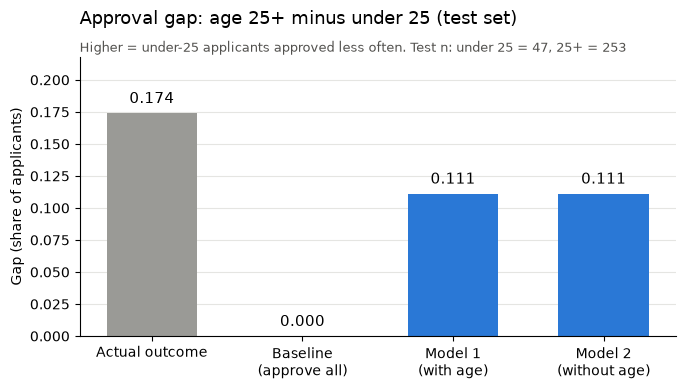

In [16]:
import matplotlib.pyplot as plt

# Gap column from the Step 10 table, in display order
order = [
    "Actual (test good rate)",
    "Baseline (approve all)",
    "Model 1 (LogReg, with age)",
    "Model 2 (LogReg, without age)",
]
gaps = final_comparison["gap"].loc[order]

labels = ["Actual outcome", "Baseline\n(approve all)", "Model 1\n(with age)", "Model 2\n(without age)"]
colors = ["#9a9a96", "#2a78d6", "#2a78d6", "#2a78d6"]   # actual = gray, models = blue

fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(labels, gaps.values, color=colors, width=0.6)

# Value on top of each bar
for i, v in enumerate(gaps.values):
    ax.text(i, v + 0.005, f"{v:.3f}", ha="center", va="bottom", fontsize=11)

ax.set_title("Approval gap: age 25+ minus under 25 (test set)", loc="left", fontsize=13, pad=24)
ax.text(0, 1.02, f"Higher = under-25 applicants approved less often. Test n: under 25 = {n_under25}, 25+ = {n_25plus}",
        transform=ax.transAxes, fontsize=9, color="#52514e")
ax.set_ylabel("Gap (share of applicants)")
ax.set_ylim(0, max(gaps.values) * 1.25)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.grid(axis="y", color="#e5e5e2", linewidth=0.8)
ax.set_axisbelow(True)

fig.tight_layout()
fig.savefig("gap_chart.png", dpi=200)
plt.show()

## Step 15: Conclusions (Phase 2)

### Question 1. Does the model treat applicants under 25 worse?
**By approval rate, yes.** On the test set, model 1 (logistic regression with age)
- approved **77.1%** of 25+ applicants and **66.0%** of under-25 applicants → **gap 0.111 (about 11 points)**
- reached accuracy 0.740, 4 points above the approve-everyone baseline (0.700).

But the model did not create this gap. **The actual repayment outcomes in the test set already differ by 0.174 (17 points)** (actual good rate: 0.727 for 25+, 0.553 for under 25). The model's gap is **smaller** than the actual gap: it approved more under-25 applicants (66%) than the share who were actually good (55%).

### Question 2. Does the gap remain without the age column?
**Yes.** Model 2 (without age)
- has accuracy 0.747 and **exactly the same group approval rates and gap (0.111)** as model 1.
- changes only 4 of 300 test predictions, all for 25+ applicants. None of the 47 under-25 decisions change.

### Why does it remain? → Age is hidden in other columns (proxies)
- A model that predicts "under 25?" from the 19 non-age columns reaches a test **ROC AUC of 0.836**, far above 0.5 (no information). Plenty of age information remains in the other columns.
- Inputs that reveal age most: male divorced/separated, management/self-employed, 7+ years at job, business loan (all traits of older applicants), and **renting** (a trait of younger applicants).
- Of these, **renting** also gets a sizable negative approval coefficient (-0.437) in the approval model, so it looks like a main channel for the age gap. The other four have small approval coefficients, so the gap likely comes from **age information spread over many columns**, not just these five.

**Key message:** "Delete the age column and age discrimination disappears" (*fairness through unawareness*) does not hold on this data. Reducing an age gap requires measuring and managing outcomes by group, not deleting a column.

### Limitations
1. **Small sample.** Only 47 test applicants are under 25; one person moves that group's approval rate by about 2 points. These results come from **one** train/test split (`random_state=42`); another split could give somewhat different numbers.
2. **One fairness criterion.** Phase 2 measures only the approval-rate gap (demographic parity). Other criteria, such as whether good applicants are approved at the same rate in each group (equal opportunity), are checked in Phase 3.
3. **The labels may be biased.** Good/bad are historical outcomes from German bank data published in 1994. If past lending conditions or screening were harder on young people, that effect may already be inside the "true" labels.
4. **Coefficients are not causes.** They show association, and for one-hot codes they are relative to other codes of the same column.
5. **Data limits:** `personal_status_sex` mixes in sex, and single women (A95) do not appear in the data. Models use default settings and a 0.5 cut-off with no tuning.

# Phase 3: Cost-based decisions and reducing the gap

## Step 16: Choose the approval threshold by cost (train set, cross-validation)

**Why look at cost?** So far the model approved when "probability of good > 0.5". But the two kinds of mistakes cost a bank different amounts. The dataset's documentation specifies this **cost matrix**:

| | Actually good | Actually bad |
|---|---|---|
| **Approve** | 0 (correct) | **5** (lent to someone who did not repay) |
| **Reject** | **1** (lost a good customer) | 0 (correct) |

- Approving a bad applicant loses the money (cost 5); rejecting a good applicant loses interest income (cost 1).
- **Total cost = 5 × (bad applicants approved) + 1 × (good applicants rejected)**. Lower is better.

**What is a threshold?** Model 2 gives each applicant a "probability of good". We **approve if probability ≥ threshold**. A higher threshold approves only surer applicants: fewer bad approvals (cost 5) but more good rejections (cost 1). We look for the lowest total cost.

**Expected answer from theory:** approving an applicant with probability p has expected cost (1 - p) × 5; rejecting costs p × 1. Approving is cheaper when (1 - p) × 5 < p, i.e. **p > 5/6 ≈ 0.83**. So the threshold should be well above 0.5.

**Choosing the threshold without touching test: 5-fold cross-validation**
- Split the 700 train applicants into 5 parts. Fit model 2 on 4 parts and predict probabilities for the 5th. Repeat 5 times, so **every train applicant gets a probability from a model that did not see them**.
- Scoring applicants that were used for fitting gives over-confident probabilities. This way the threshold is chosen on probabilities that behave like those for new applicants.
- With these probabilities we try thresholds 0.01-0.99 and pick the one with the **lowest train total cost**. **The test set is not used at all.**

**Code**
- `StratifiedKFold(n_splits=5, shuffle=True, random_state=42)`: 5 parts that keep the good/bad ratio (fixed for reproducibility)
- `cross_val_predict(clone(model2), ..., method="predict_proba")`: does the 5 rounds above in one line. `clone` is an unfitted copy of model 2. `[:, 1]` keeps the probability of good.
- `total_cost(true, predicted)`: total cost from the cost matrix. `&` means "and".
- `thresholds = [i / 100 for i in range(1, 100)]`: 0.01, 0.02, ..., 0.99
- `train_costs.idxmin()`: the threshold with the lowest total cost

In [17]:
from sklearn.model_selection import StratifiedKFold, cross_val_predict

# Cost matrix: approve a bad applicant = 5, reject a good applicant = 1
def total_cost(y_true, y_pred):
    approve_bad = ((y_pred == 1) & (y_true == 0)).sum()
    reject_good = ((y_pred == 0) & (y_true == 1)).sum()
    return 5 * approve_bad + 1 * reject_good

# 5-fold cross-validation inside train: probabilities "as if unseen"
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
train_prob = cross_val_predict(clone(model2), X_train_no_age, y_train, cv=cv, method="predict_proba")[:, 1]
train_prob = pd.Series(train_prob, index=X_train.index)

# Try thresholds 0.01-0.99 and compute the train total cost for each
thresholds = [i / 100 for i in range(1, 100)]
train_costs = pd.Series(
    [total_cost(y_train, (train_prob >= t).astype(int)) for t in thresholds],
    index=thresholds,
)

cost_threshold = train_costs.idxmin()
print("Lowest-cost threshold:", cost_threshold)          # theory: 5/6 = about 0.83
print("Train total cost at that threshold:", train_costs.min())
print("Train total cost at the default 0.5:", train_costs[0.5])
print()
print("5 lowest-cost thresholds:")
print(train_costs.sort_values().head(5))

Lowest-cost threshold: 0.88
Train total cost at that threshold: 381
Train total cost at the default 0.5: 647

5 lowest-cost thresholds:
0.88    381
0.85    382
0.86    382
0.82    384
0.84    385
dtype: int64


## Step 17: Apply the cost-based threshold to the test set

The threshold chosen from train only in Step 16 (`cost_threshold`, 0.88 in this run) is now applied to test for the first time. The threshold is already fixed, so test is used **only for evaluation**.

**What we compute**
- **accuracy**: share correct
- **total cost**: same cost matrix as Step 16 (approve bad = 5, reject good = 1), over the 300 test applicants
- **approval rate by group and gap**: as before
- **"good-applicant approval rate" by group**: among applicants who were **actually good**, the share approved. Step 18 equalizes this across groups, so we show it now.
  - Its formal name is the **true positive rate (TPR)**. Equal TPR across groups is called **equal opportunity**: applicants able to repay are approved with the same probability regardless of age.

**Code**
- `model2.predict_proba(X_test_no_age)[:, 1]`: each test applicant's probability of good. Model 2 is not refit.
- `(test_prob >= cost_threshold).astype(int)`: 1 (approve) if the probability is at least `cost_threshold`, else 0 (reject)
- `evaluate(pred)`: computes all the metrics above and returns them as a dictionary. It is reused in the next steps.
  - `y_test == 1`: True for applicants who were actually good
  - `pred[good].groupby(group_test[good]).mean()`: approval rate per group among actually-good applicants = good-applicant approval rate per group
- For comparison, the default model 2 (threshold 0.5) is evaluated with the same function and shown side by side.

In [18]:
def evaluate(pred):
    """Metrics on the test set for predictions (1 = approve, 0 = reject)."""
    rates = pred.groupby(group_test).mean()                    # approval rate by group
    good = y_test == 1                                          # actually-good applicants
    good_rates = pred[good].groupby(group_test[good]).mean()    # good-applicant approval rate by group
    return {
        "accuracy": accuracy_score(y_test, pred),
        "total_cost": total_cost(y_test, pred),
        "approval_under25": rates["under 25"],
        "approval_25plus": rates["25+"],
        "good_approval_under25": good_rates["under 25"],
        "good_approval_25plus": good_rates["25+"],
        "gap": rates["25+"] - rates["under 25"],
    }

# Model 2's probability of good for each test applicant (not refit)
test_prob = pd.Series(model2.predict_proba(X_test_no_age)[:, 1], index=X_test.index)

# Approve/reject with the cost-based threshold
cost_pred = (test_prob >= cost_threshold).astype(int)

result_default = evaluate(model2_pred)   # default (threshold 0.5)
result_cost = evaluate(cost_pred)        # cost-based (threshold = cost_threshold)

pd.DataFrame(
    {"Model 2 (default, 0.5)": result_default, f"Model 2 + cost threshold ({cost_threshold})": result_cost}
).round(3)

,"Model 2 (default, 0.5)",Model 2 + cost threshold (0.88)
accuracy,0.747,0.583
total_cost,260.000,161.000
approval_under25,0.660,0.191
approval_25plus,0.771,0.372
good_approval_under25,0.731,0.308
good_approval_25plus,0.875,0.467
gap,0.111,0.180


## Step 18: Reducing the gap - a separate threshold for under-25 applicants (train set)

With the cost-based threshold (`cost_threshold`, 0.88 in this run) in Step 17, only 31% of under-25 applicants who actually repaid (good) were approved, versus 47% of good 25+ applicants. We try to close this difference.

**Goal: equal opportunity**
- Make the **share of actually-good applicants who get approved** (good-applicant approval rate) similar in both groups.
- Meaning: "if you are able to repay, your chance of approval should not depend on your age."

**Method**
1. **Keep 25+ as is:** threshold `cost_threshold` (the cost-based threshold from Step 16)
2. Measure the 25+ good-applicant approval rate on train → this is the **target**.
3. Try thresholds 0.01-0.99 **for under-25 applicants only** and pick the one whose under-25 good-applicant approval rate is **closest** to the target.

**Test is not used.** We use only the train cross-validation probabilities from Step 16 (`train_prob`), because probabilities for applicants the model was fitted on are over-confident.

**Caution: this method uses age directly.** The approval threshold differs by age group, so even though model 2's inputs exclude age, the decision step uses age again. In real lending this may raise legal or regulatory issues. This is discussed in the write-up.

**Small-sample caution:** train has 102 under-25 applicants, only 62 of them good, so the chosen threshold can be unstable.

**Code**
- `group_train = group.loc[X_train.index]`: age group of each train applicant (same as `group_test` in Step 5)
- `old_good`, `young_good`: True/False columns for "25+ and good" and "under 25 and good" in train
- `(train_prob[old_good] >= cost_threshold).mean()`: share of good 25+ applicants approved = target
- `abs(...)`: distance from the target. `.idxmin()` picks the threshold with the smallest distance.

In [19]:
# Age group of each train applicant
group_train = group.loc[X_train.index]

old_good = (group_train == "25+") & (y_train == 1)         # 25+ and good
young_good = (group_train == "under 25") & (y_train == 1)  # under 25 and good
print("Good applicants in train: 25+ =", old_good.sum(), "/ under 25 =", young_good.sum())

# Target: 25+ good-applicant approval rate at cost_threshold (train cross-validation probabilities)
target_rate = (train_prob[old_good] >= cost_threshold).mean()
print("Target (25+ good-applicant approval rate, train):", round(target_rate, 3))

# Try under-25 thresholds and measure the distance from the target
diff = pd.Series(
    [abs((train_prob[young_good] >= t).mean() - target_rate) for t in thresholds],
    index=thresholds,
)
young_threshold = diff.idxmin()
young_rate = (train_prob[young_good] >= young_threshold).mean()

print()
print("Under-25 threshold:", young_threshold, " (25+ stays at", cost_threshold, ")")
print("Under-25 good-applicant approval rate at that threshold (train):", round(young_rate, 3))

Good applicants in train: 25+ = 428 / under 25 = 62
Target (25+ good-applicant approval rate, train): 0.474

Under-25 threshold: 0.83  (25+ stays at 0.88 )
Under-25 good-applicant approval rate at that threshold (train): 0.468


## Step 19: Comparison - default / cost-based / gap reduction (test set)

We apply the two thresholds chosen on train in Step 18 to the test set and compare the three versions in one table.

| Version | 25+ threshold | Under-25 threshold |
|---|---|---|
| Model 2 (default) | 0.5 | 0.5 |
| Model 2 + cost threshold | `cost_threshold` (0.88) | `cost_threshold` (0.88) |
| Model 2 + gap reduction | `cost_threshold` (0.88) | **`young_threshold` (0.83)** |

Values in parentheses are from this run (random_state=42); the code always uses the variables.

**Rows (all on the 300 test applicants)**
- `accuracy`, `total_cost`: share correct; total cost from the cost matrix (approve bad = 5, reject good = 1)
- `approval_under25`, `approval_25plus`: approval rate by group
- `good_approval_under25`, `good_approval_25plus`: **good-applicant approval rate** by group (share of actually-good applicants approved)
- `gap`: approval-rate gap (25+ minus under 25)
- `good_approval_gap`: good-applicant approval-rate gap (25+ minus under 25). This is **what gap reduction directly targets**, so we show it too.

**Reading caution:** only 26 good test applicants are under 25, so their approval rate moves by about 4 points per person.

**Code**
- `[young_threshold if g == "under 25" else cost_threshold for g in group_test]`: goes through the test applicants one by one and picks `young_threshold` for under 25, otherwise `cost_threshold` → each applicant's own threshold
- `test_prob >= person_threshold`: compares each applicant with their own threshold to approve or reject
- `evaluate(...)`: the function from Step 17
- `pd.DataFrame({name: result, ...})`: three result dictionaries become a three-column table.

In [20]:
# Each applicant's threshold: under 25 = young_threshold, 25+ = cost_threshold
person_threshold = pd.Series(
    [young_threshold if g == "under 25" else cost_threshold for g in group_test],
    index=X_test.index,
)
fair_pred = (test_prob >= person_threshold).astype(int)

result_fair = evaluate(fair_pred)

phase3_table = pd.DataFrame({
    "Model 2 (default)": result_default,
    "Model 2 + cost threshold": result_cost,
    "Model 2 + gap reduction": result_fair,
})

# Good-applicant approval-rate gap (what gap reduction targets)
phase3_table.loc["good_approval_gap"] = (
    phase3_table.loc["good_approval_25plus"] - phase3_table.loc["good_approval_under25"]
)

print("Good test applicants: under 25 =", ((group_test == "under 25") & (y_test == 1)).sum(),
      "/ 25+ =", ((group_test == "25+") & (y_test == 1)).sum())
phase3_table.round(3)

Good test applicants: under 25 = 26 / 25+ = 184


,Model 2 (default),Model 2 + cost threshold,Model 2 + gap reduction
accuracy,0.747,0.583,0.593
total_cost,260.000,161.000,158.000
approval_under25,0.660,0.191,0.255
approval_25plus,0.771,0.372,0.372
good_approval_under25,0.731,0.308,0.423
good_approval_25plus,0.875,0.467,0.467
gap,0.111,0.180,0.116
good_approval_gap,0.144,0.160,0.044


## Step 20: Approval rate by group, per version (for the presentation)

The group approval rates from the Step 19 table, side by side for each version. Each version has two bars (under 25, 25+), so the height difference is the gap.

**Design**
- **Orange = under 25, blue = 25+.** This color pair passed a color-blindness separation check. A legend is included.
- Approval rates are written on the bars, and each version's gap is written under its name.

**Code**
- `x = list(range(3))`: positions 0, 1, 2 for the three versions
- `[i - width / 2 for i in x]`, `[i + width / 2 for i in x]`: shift half a bar left (under 25) and right (25+) so the bars sit side by side.
- `ax.bar(positions, values, width, label=name, color=color)`: draws one set of bars. `label` is used in the legend. `edgecolor="white"` leaves a thin white gap between touching bars.
- The threshold numbers in `names` come from the `cost_threshold` and `young_threshold` variables rather than being typed in, so the chart stays correct if earlier steps change.
- `ax.text(...)`: writes values on the bars.
- `ax.set_xticks(x, labels)`: version names (and gaps) on the x-axis.
- `fig.savefig("approval_rates_chart.png", dpi=200)`: saves a PNG for the slides.

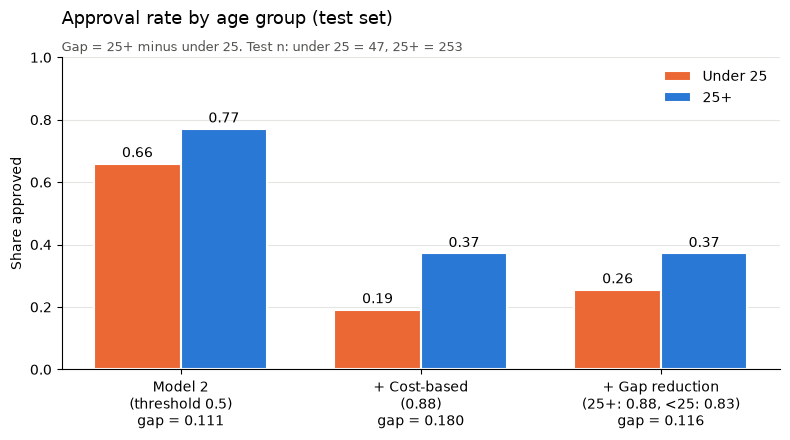

In [21]:
methods = ["Model 2 (default)", "Model 2 + cost threshold", "Model 2 + gap reduction"]
names = [
    "Model 2\n(threshold 0.5)",
    f"+ Cost-based\n({cost_threshold})",
    f"+ Gap reduction\n(25+: {cost_threshold}, <25: {young_threshold})",
]

under = phase3_table.loc["approval_under25", methods].values
older = phase3_table.loc["approval_25plus", methods].values
gaps = phase3_table.loc["gap", methods].values

x = list(range(3))
width = 0.36

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.bar([i - width / 2 for i in x], under, width, label="Under 25", color="#eb6834", edgecolor="white", linewidth=1.5)
ax.bar([i + width / 2 for i in x], older, width, label="25+", color="#2a78d6", edgecolor="white", linewidth=1.5)

# Approval rate on top of each bar
for i in x:
    ax.text(i - width / 2, under[i] + 0.01, f"{under[i]:.2f}", ha="center", va="bottom", fontsize=10)
    ax.text(i + width / 2, older[i] + 0.01, f"{older[i]:.2f}", ha="center", va="bottom", fontsize=10)

# x-axis: version name + gap
ax.set_xticks(x, [f"{n}\ngap = {g:.3f}" for n, g in zip(names, gaps)])

ax.set_title("Approval rate by age group (test set)", loc="left", fontsize=13, pad=24)
ax.text(0, 1.02, f"Gap = 25+ minus under 25. Test n: under 25 = {n_under25}, 25+ = {n_25plus}",
        transform=ax.transAxes, fontsize=9, color="#52514e")
ax.set_ylabel("Share approved")
ax.set_ylim(0, 1)
ax.legend(frameon=False, loc="upper right")
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.grid(axis="y", color="#e5e5e2", linewidth=0.8)
ax.set_axisbelow(True)

fig.tight_layout()
fig.savefig("approval_rates_chart.png", dpi=200)
plt.show()

# Phase 4: Failure analysis and demo

## Step 21: Good applicants under 25 who were rejected (test set)

**Decision rule:** model 2 + cost-based threshold (`cost_threshold`, 0.88 in this run; `cost_pred` from Step 17), the rule a bank would most plausibly use.

**Who:** test applicants who meet all three conditions
1. under 25
2. actually **good** (repaid)
3. **rejected** by the model → a "lost good customer" for the bank and an "unfair rejection" for the applicant.

In the Step 19 table, the good-applicant approval rate for under 25 was 0.308, so 18 of 26 applicants fall here.

**Columns shown (key inputs only)**
- `good_prob`: model 2's probability of good. It is below `cost_threshold`, which is why they were rejected. Sorting from highest puts the **near misses** at the top.
- `age`, `duration_months`, `credit_amount`: age, loan duration (months), loan amount (DM)
- `checking_status`, `credit_history`, `savings`, `employment_since`, `housing`, `purpose`: shown with their meanings from the Step 2-2 `code_table`.
- `reason`: **left empty**, to be filled in by hand after looking at each case. (The function in the next step computes the model's own reasons.)

**Code**
- `mask = (group_test == "under 25") & (y_test == 1) & (cost_pred == 0)`: the three conditions joined with `&` (and)
- `X_test.loc[mask, columns]`: key inputs of the matching applicants. `.copy()` avoids touching the original `X_test`.
- `code_meaning`: dictionary from code to meaning. Codes such as `A11` never repeat across columns, so one dictionary is enough.
- `.replace(code_meaning)`: replaces the codes in the table with their meanings.
- `.sort_values("good_prob", ascending=False)`: sorts from the highest probability.

In [22]:
# Under 25 + actually good + rejected at the cost threshold
mask = (group_test == "under 25") & (y_test == 1) & (cost_pred == 0)
print("Good under-25 applicants who were rejected:", mask.sum(), "of",
      ((group_test == "under 25") & (y_test == 1)).sum())

show_cols = [
    "age", "duration_months", "credit_amount", "checking_status",
    "credit_history", "savings", "employment_since", "housing", "purpose",
]

rejected_young = X_test.loc[mask, show_cols].copy()

# Code (A11, ...) -> meaning
code_meaning = dict(zip(code_table["code"], code_table["meaning"]))
rejected_young = rejected_young.replace(code_meaning)

# Model 2's probability of good (below cost_threshold, so rejected)
rejected_young.insert(0, "good_prob", test_prob[mask].round(3))

# Reason: to be filled in by hand
rejected_young["reason"] = ""

rejected_young.sort_values("good_prob", ascending=False)

Good under-25 applicants who were rejected: 18 of 26


,good_prob,age,duration_months,credit_amount,checking_status,credit_history,savings,employment_since,housing,purpose,reason
480,0.877,23,12,3573,0 <= balance < 200 DM,critical account / credits at other banks,< 100 DM,1 to < 4 years,own,radio/television,
391,0.866,19,12,983,0 <= balance < 200 DM,existing credits paid back duly till now,>= 1000 DM,< 1 year,rent,furniture/equipment,
122,0.845,24,12,1768,no checking account,existing credits paid back duly till now,< 100 DM,1 to < 4 years,rent,furniture/equipment,
217,0.824,23,36,3913,balance >= 200 DM / salary paid in for 1+ year,existing credits paid back duly till now,< 100 DM,1 to < 4 years,own,radio/television,
67,0.770,22,12,1007,0 <= balance < 200 DM,existing credits paid back duly till now,>= 1000 DM,1 to < 4 years,own,car (new),
752,0.770,23,12,841,0 <= balance < 200 DM,existing credits paid back duly till now,100 to < 500 DM,4 to < 7 years,rent,business,
82,0.747,24,18,1568,no checking account,existing credits paid back duly till now,100 to < 500 DM,1 to < 4 years,rent,business,
134,0.724,21,60,10144,no checking account,existing credits paid back duly till now,100 to < 500 DM,4 to < 7 years,own,radio/television,
802,0.633,24,20,4272,balance < 0 DM,critical account / credits at other banks,< 100 DM,>= 7 years,own,furniture/equipment,
152,0.598,24,36,5848,balance >= 200 DM / salary paid in for 1+ year,existing credits paid back duly till now,< 100 DM,1 to < 4 years,own,radio/television,


## Step 22: A function that explains one applicant

`explain_applicant` takes one applicant and returns
1. **Decision**: approve / reject (model 2 + cost-based threshold `cost_threshold`)
2. **Approval probability**: model 2's probability of good
3. **Top 3 reasons**: the three inputs that pushed the decision the most

### How reasons are computed: coefficient × value
Logistic regression builds a score like this:

> **score = intercept + (coef₁ × value₁) + (coef₂ × value₂) + ...**, and probability = the score squashed into 0-1

So each **coefficient × value** shows how much that input raised (+) or lowered (-) the score.
- **Categorical (one-hot)**: only the applicant's own code has value 1; the others are 0. So the contribution is that code's coefficient. Example: renting → the coefficient of `housing_A151`
- **Numeric (scaled)**: the value is "how many standard deviations from the mean". Above the mean is +, below is -. So for an input with a negative coefficient, such as loan duration, a **longer** loan lowers the score and a **shorter** one raises it.

**Which three?**
- **Rejected**: the three that **lowered** the score the most (most negative contributions)
- **Approved**: the three that **raised** it the most (most positive contributions)
- i.e. "the biggest reasons pushing the decision that way".

**Caution:** categorical coefficients are relative to other codes of the same column (as in Step 12). These reasons describe how this model sees the applicant; they do not prove real-world causes.

### Code
- `applicant`: one applicant, a **one-row DataFrame** with the same columns as `X`. `age` may be present; model 2 does not use it, so `drop(columns="age", errors="ignore")` removes it. `errors="ignore"` means "no error if `age` is absent".
- `pre.transform(row)`: applies model 2's preprocessing (one-hot + scaling). If the result is a sparse matrix (a format that skips storing zeros), `.toarray()` turns it into a normal array.
- `coef * values`: coefficient × value per input = contribution
- `readable(name)`: turns names like `cat__housing_A151` into `housing = rent`. Numeric inputs show the actual value.
- `.sort_values()`: sorts contributions from smallest. For a rejection take the first 3 (`head`); for an approval take the last 3 (`tail`) in reverse.
- `float(...)`: converts numpy numbers into plain Python numbers so the output reads `0.877` instead of `np.float64(0.877)`.

In [23]:
def explain_applicant(applicant):
    """One applicant (one-row DataFrame) -> decision, approval probability, top 3 reasons (model 2 + cost threshold)."""
    row = applicant.drop(columns="age", errors="ignore")   # model 2 does not use age

    # 1) Approval probability and decision
    prob = model2.predict_proba(row)[0, 1]
    decision = "approve" if prob >= cost_threshold else "reject"

    # 2) Contribution of each input = coefficient x value
    pre = model2.named_steps["preprocess"]
    values = pre.transform(row)
    if hasattr(values, "toarray"):        # sparse matrix -> normal array
        values = values.toarray()
    coef = model2.named_steps["logreg"].coef_[0]
    contrib = pd.Series(coef * values[0], index=pre.get_feature_names_out())

    # 3) Readable names: "cat__housing_A151" -> "housing = rent"
    def readable(name):
        kind, rest = name.split("__")
        if kind == "num":
            return f"{rest} = {row[rest].iloc[0]}"
        col, code = rest.rsplit("_", 1)
        return f"{col} = {code_meaning.get(code, code)}"

    # 4) The three inputs that pushed hardest toward the decision
    ordered = contrib.sort_values()
    top3 = ordered.head(3) if decision == "reject" else ordered.tail(3)[::-1]
    reasons = [(readable(name), round(float(value), 3)) for name, value in top3.items()]

    return {"decision": decision, "approval_prob": round(float(prob), 3), "reasons": reasons}


# Example 1: top row of the Step 21 table (the rejected good under-25 applicant with the highest probability)
near_miss_id = rejected_young["good_prob"].idxmax()
print(f"Example 1 (test applicant {near_miss_id}):")
print(explain_applicant(X_test.loc[[near_miss_id]]))
print()

# Example 2: one of the approved applicants
approved_id = cost_pred[cost_pred == 1].index[0]
print(f"Example 2 (test applicant {approved_id}):")
print(explain_applicant(X_test.loc[[approved_id]]))

Example 1 (test applicant 480):
{'decision': 'reject', 'approval_prob': 0.877, 'reasons': [('savings = < 100 DM', -0.726), ('foreign_worker = yes', -0.598), ('checking_status = 0 <= balance < 200 DM', -0.347)]}

Example 2 (test applicant 80):
{'decision': 'approve', 'approval_prob': 0.939, 'reasons': [('checking_status = no checking account', 0.812), ('other_installment_plans = none', 0.446), ('installment_rate = 1', 0.414)]}


## Step 23: Does changing only the age to 30 change the outcome? (model 1)

**Question:** keeping everything else the same and changing **only age** to 30, does approve/reject change?
This kind of "what if" comparison is a **counterfactual test**. If the outcome changes, the model changes its decision because of **age itself**.

**Why model 1?** Model 2 does not take `age` as an input, so changing age can never change its result. Only **model 1** (Step 7), which uses age directly, makes this test meaningful.
- Model 1 decides with a threshold of **0.5** (approve if probability >= 0.5), the same `>=` rule used for every threshold in this notebook.

**What this test cannot show:** changing age leaves **proxy variables** such as job tenure and housing unchanged. So it measures only the **direct** effect of the age column, not the **indirect** effect through proxies seen in Steps 11-13.

**Code**
- `age_counterfactual(applicant, new_age=30)`: takes one applicant and returns the probability and decision at the original age and at the new age (keys `new_prob`, `new_decision`, so they stay the same for any `new_age`). `new_age=30` means 30 is used unless another age is given.
- `changed = applicant.copy()`, `changed["age"] = new_age`: a copy with only the age changed; the original is untouched.
- `model1.predict_proba(...)[0, 1]`: model 1's probability of good
- Below the function, the same test is run on **all 47 under-25 test applicants**, counting how many decisions change and how much the probability moves on average.

In [24]:
def age_counterfactual(applicant, new_age=30):
    """Compare model 1 (approve if prob >= 0.5) for one applicant at their own age and at new_age."""
    changed = applicant.copy()
    changed["age"] = new_age

    prob_before = model1.predict_proba(applicant)[0, 1]
    prob_after = model1.predict_proba(changed)[0, 1]
    decision_before = "approve" if prob_before >= 0.5 else "reject"
    decision_after = "approve" if prob_after >= 0.5 else "reject"

    return {
        "original_age": int(applicant["age"].iloc[0]),
        "original_prob": round(float(prob_before), 3),
        "original_decision": decision_before,
        "new_age": new_age,
        "new_prob": round(float(prob_after), 3),
        "new_decision": decision_after,
        "decision_changed": decision_before != decision_after,
    }


# Example: the same applicant as Example 1 in Step 22
print(f"Example (test applicant {near_miss_id}):")
print(age_counterfactual(X_test.loc[[near_miss_id]]))
print()

# Same test on all 47 under-25 test applicants
young_ids = X_test.index[group_test == "under 25"]
results = pd.DataFrame([age_counterfactual(X_test.loc[[i]]) for i in young_ids], index=young_ids)

print("Under-25 test applicants:", len(results), "| decisions changed when age set to 30:", results["decision_changed"].sum())
print("Average change in approval probability:", round((results["new_prob"] - results["original_prob"]).mean(), 3))

Example (test applicant 480):
{'original_age': 23, 'original_prob': 0.862, 'original_decision': 'approve', 'new_age': 30, 'new_prob': 0.876, 'new_decision': 'approve', 'decision_changed': False}



Under-25 test applicants: 47 | decisions changed when age set to 30: 0
Average change in approval probability: 0.022


## Step 24: Demo app setup - build an applicant from 7 inputs and compute results

The demo app (Gradio) asks for only **7** key inputs.
- Numbers: **age**, **loan duration** (months), **loan amount** (DM)
- Choices: **credit history**, **savings**, **employment since**, **housing**

**The other 13 columns?** Filled with the **most common value in the train set** (the mode). For example, `job` gets "skilled employee / official", the most common in train. This keeps the form short, so app results assume "otherwise a typical applicant".

**What the app shows (reusing the Step 22 and 23 functions)**
1. **Decision** and **approval probability**: model 2 + cost-based threshold (`cost_threshold`) → `explain_applicant`
2. **Top 3 reasons**: coefficient × value → `explain_applicant`
3. **Result if age were 30**: model 1 (default threshold 0.5) → `age_counterfactual`. The model and threshold differ from item 1, so the screen labels them separately.

**This cell does not launch the app.** It only defines the functions and checks one example without Gradio. The app is launched in the last cell, so the notebook runs to the end without the app.

**Code**
- `X_train.mode().iloc[0]`: the most common value of each column in train. `.mode()` returns a table and `.iloc[0]` is its first row.
- `make_applicant(...)`: copies the mode dictionary, replaces the 7 inputs, and returns a one-row DataFrame.
- `choices(col)`: dropdown options as (meaning, code) pairs. The meaning is shown on screen and the code goes into the model. Only codes that appear in train are offered.
- `app_predict(...)`: runs when the app button is pressed. 7 inputs → 4 text results (decision, probability, reasons, age test). If age, duration or amount is left empty (`None`), it returns a message instead of crashing.

In [25]:
# Fill the other columns with the most common value in train
defaults = X_train.mode().iloc[0].to_dict()


def make_applicant(age, duration_months, credit_amount, credit_history, savings, employment_since, housing):
    """7 inputs + modes for the rest -> one-row DataFrame with the same columns as X."""
    values = dict(defaults)
    values.update({
        "age": int(age),
        "duration_months": int(duration_months),
        "credit_amount": int(credit_amount),
        "credit_history": credit_history,
        "savings": savings,
        "employment_since": employment_since,
        "housing": housing,
    })
    return pd.DataFrame([values])[X.columns]


def choices(col):
    """Dropdown options: (meaning, code), only codes that appear in train."""
    return [(code_meaning[c] + f" ({c})", c) for c in sorted(X_train[col].unique())]


def app_predict(age, duration_months, credit_amount, credit_history, savings, employment_since, housing):
    if age is None or duration_months is None or credit_amount is None:   # an empty number box gives None
        return "Please fill in age, loan duration and credit amount.", "", "", ""

    applicant = make_applicant(age, duration_months, credit_amount, credit_history, savings, employment_since, housing)

    result = explain_applicant(applicant)                   # model 2 + cost threshold
    reasons = "\n".join(f"{i}. {text}  (contribution {value:+.3f})" for i, (text, value) in enumerate(result["reasons"], 1))

    cf = age_counterfactual(applicant, new_age=30)          # model 1, threshold 0.5
    age_text = (
        f"[Model 1, threshold 0.5] age {cf['original_age']}: {cf['original_decision']} (prob {cf['original_prob']})\n"
        f"-> at age {cf['new_age']}: {cf['new_decision']} (prob {cf['new_prob']})\n"
        + ("Decision changed" if cf["decision_changed"] else "Decision unchanged")
    )

    decision = f"{result['decision']}  (model 2, threshold {cost_threshold})"
    return decision, f"{result['approval_prob']:.3f}", reasons, age_text


# Check without the app: age 22, 24 months, 3000 DM, other choices = train mode
print("Some of the fill-in values (mode):", {k: defaults[k] for k in ["job", "purpose", "checking_status"]})
print()
example = app_predict(22, 24, 3000, defaults["credit_history"], defaults["savings"],
                      defaults["employment_since"], defaults["housing"])
for label, text in zip(["Decision", "Approval probability", "Top 3 reasons", "Age test"], example):
    print(f"[{label}]\n{text}\n")

Some of the fill-in values (mode): {'job': 'A173', 'purpose': 'A43', 'checking_status': 'A14'}

[Decision]
reject  (model 2, threshold 0.88)

[Approval probability]
0.807

[Top 3 reasons]
1. savings = < 100 DM  (contribution -0.726)
2. foreign_worker = yes  (contribution -0.598)
3. other_debtors = none  (contribution -0.331)

[Age test]
[Model 1, threshold 0.5] age 22: approve (prob 0.785)
-> at age 30: approve (prob 0.808)
Decision unchanged



## Step 25: Launch the demo app (Gradio) - last cell of the notebook

**The notebook runs to the end without the app:** this cell defaults to `RUN_APP = False`, so **Run All does not launch the app**; it only prints a note.

**To launch the app**
1. If Gradio is not installed, uncomment and run the `%pip install gradio` line below once. Gradio is not one of the core libraries (pandas, scikit-learn, matplotlib); it is added only for the demo.
2. With all cells above already run, change `RUN_APP = False` to **`True`** and re-run **only this cell**.
3. The app appears inside the notebook, and a browser address (usually `http://127.0.0.1:7860`) is printed.
4. To stop it, run `demo.close()`.

**Layout (`gr.Interface`)**
- 7 inputs: 3 number boxes (`gr.Number`) and 4 dropdowns (`gr.Dropdown`). Dropdowns show each meaning with its code.
- Starting values: age 22, 24 months, 3000 DM; dropdowns start at the train mode.
- 4 outputs (`gr.Textbox`): decision, approval probability, top 3 reasons, result at age 30
- Pressing the button runs `app_predict` from Step 24.

**Code**
- `import gradio as gr` sits **inside** `if RUN_APP:` so Run All finishes without errors on a computer without Gradio.
- `gr.Interface(fn=function, inputs=[...], outputs=[...])`: wraps one function in a web page with input and output boxes. The order of `inputs` must match the arguments of `app_predict`.
- `demo.launch()`: starts the app.

In [26]:
# %pip install gradio   # run once if Gradio is not installed

RUN_APP = False   # set to True and re-run only this cell to launch the app

if RUN_APP:
    import gradio as gr

    demo = gr.Interface(
        fn=app_predict,
        inputs=[
            gr.Number(label="Age", value=22, precision=0),
            gr.Number(label="Loan duration, months", value=24, precision=0),
            gr.Number(label="Loan amount, DM", value=3000, precision=0),
            gr.Dropdown(choices("credit_history"), value=defaults["credit_history"], label="Credit history"),
            gr.Dropdown(choices("savings"), value=defaults["savings"], label="Savings"),
            gr.Dropdown(choices("employment_since"), value=defaults["employment_since"], label="Employment since"),
            gr.Dropdown(choices("housing"), value=defaults["housing"], label="Housing"),
        ],
        outputs=[
            gr.Textbox(label="Decision"),
            gr.Textbox(label="Approval probability (probability of good)"),
            gr.Textbox(label="Top 3 reasons (coefficient x value)", lines=3),
            gr.Textbox(label="What if the applicant were 30?", lines=3),
        ],
        title="Loan Approval Fairness Demo (German Credit)",
        description="Columns other than these 7 are filled with the most common value in the training set. Decision: model 2 (without age) + cost-based threshold. Age test: model 1 (with age) + threshold 0.5.",
    )
    demo.launch()
else:
    print("App not launched. To launch it, set RUN_APP = True and re-run only this cell.")

App not launched. To launch it, set RUN_APP = True and re-run only this cell.
